In [1]:
from Board import DartBoard
import cv2
import matplotlib.pyplot as plt
import numpy as np
%load_ext autoreload
%autoreload 2

In [2]:

"""Play original and processed video side by side. Press q to quit."""

import cv2
import numpy as np
from Board import DartBoard

VIDEO_PATH = r"..\data\videos\white_background_yesHuman.mp4"

DISPLAY_WIDTH = 640
DISPLAY_HEIGHT = 640
RETRY_EVERY_N_FRAMES = 30
CACHE_BOARD = True
CAMERA_ON = True
INIT_FRAMES = []


def main():
    frame_count = 0
    init_frames = []
    board = DartBoard()

    if CAMERA_ON:
        PATH = 1
    else:
        PATH = VIDEO_PATH

    cap = cv2.VideoCapture(PATH)

    if not cap.isOpened():
        cap.release()
        raise FileNotFoundError(f"Cannot open video: {PATH}")

    try:
        once_frame = False
        while True:
            ret, frame = cap.read()

            if not ret:
                break

            if not once_frame:
                reference_frame = frame.copy()
                once_frame = True
            else:
                difference = cv2.absdiff(frame, reference_frame)
                mean_difference = np.mean(difference) / 255.0
                if mean_difference > 0.01:
                    reference_frame = frame.copy()
            original = reference_frame.copy()
            # else:
            #     original = frame.copy()

            board.update_frame(frame)
            frame_count += 1

            if len(init_frames) < 10:
                init_frames.append(frame.copy())
                print(f"Collected Initial Frames: {len(init_frames)}")

                if len(init_frames) == 10:
                    board.calibrate(init_frames)

            if board.board_homography is not None:
                if (
                    not CACHE_BOARD
                    or board.field_map is None
                    or frame_count % RETRY_EVERY_N_FRAMES == 0
                ):
                    board.detect()

                processed = board.draw()
            else:
                processed = board.frame.copy()

            # Resize both outputs
            original = cv2.resize(
                original, (DISPLAY_WIDTH, DISPLAY_HEIGHT)
            )

            processed = cv2.resize(
                processed, (DISPLAY_WIDTH, DISPLAY_HEIGHT)
            )

            if len(processed.shape) == 2:
                processed = cv2.cvtColor(
                    processed, cv2.COLOR_GRAY2BGR
                )

            cv2.putText(
                original, "Original",
                (20, 40),
                cv2.FONT_HERSHEY_SIMPLEX,
                1, (0, 255, 0), 2
            )

            cv2.putText(
                processed, "Processed",
                (20, 40),
                cv2.FONT_HERSHEY_SIMPLEX,
                1, (0, 255, 0), 2
            )

            # Combine frames horizontally
            combined = np.hstack((original, processed))

            cv2.imshow("Original | Processed", combined)

            if cv2.waitKey(5) & 0xFF == ord("q"):
                break

    finally:
        cap.release()
        cv2.destroyAllWindows()


if __name__ == "__main__":
    main()


Collected Initial Frames: 1
Collected Initial Frames: 2
Collected Initial Frames: 3
Collected Initial Frames: 4
Collected Initial Frames: 5
Collected Initial Frames: 6
Collected Initial Frames: 7
Collected Initial Frames: 8
Collected Initial Frames: 9
Collected Initial Frames: 10


In [3]:

"""Record frame differences to determine an optimal detection threshold.

SPACE = Mark a dart landing
R     = Reset reference frame
Q     = Quit and save
"""

import cv2
import numpy as np
import csv
import time

VIDEO_PATH = r"..\data\videos\white_background_yesHuman.mp4"
CAMERA_ON = True
CAMERA_INDEX = 0

DISPLAY_WIDTH = 640
DISPLAY_HEIGHT = 640

CSV_PATH = "frame_differences.csv"


def main():
    path = CAMERA_INDEX if CAMERA_ON else VIDEO_PATH
    cap = cv2.VideoCapture(path)

    if not cap.isOpened():
        raise RuntimeError(f"Cannot open video: {path}")

    reference_frame = None
    measurements = []
    frame_count = 0
    max_difference = 0.0
    start_time = time.time()

    try:
        while True:
            ret, frame = cap.read()

            if not ret:
                break

            frame_count += 1

            if reference_frame is None:
                reference_frame = frame.copy()

            # Calculate frame difference
            difference = cv2.absdiff(frame, reference_frame)
            gray_difference = cv2.cvtColor(
                difference, cv2.COLOR_BGR2GRAY
            )

            mean_difference = float(np.mean(difference))
            max_pixel_difference = int(np.max(gray_difference))

            # Percentage of pixels changed significantly
            changed_percentage = float(
                np.mean(gray_difference > 30) * 100
            )

            max_difference = max(
                max_difference, mean_difference
            )

            timestamp = time.time() - start_time

            # Store measurements
            measurement = {
                "frame": frame_count,
                "time": round(timestamp, 3),
                "mean_difference": round(mean_difference, 3),
                "max_pixel_difference": max_pixel_difference,
                "changed_percentage": round(changed_percentage, 3),
                "dart_landed": 0
            }

            measurements.append(measurement)

            # Prepare display
            original_display = cv2.resize(
                frame.copy(),
                (DISPLAY_WIDTH, DISPLAY_HEIGHT)
            )

            difference_display = cv2.resize(
                gray_difference,
                (DISPLAY_WIDTH, DISPLAY_HEIGHT)
            )

            difference_display = cv2.cvtColor(
                difference_display, cv2.COLOR_GRAY2BGR
            )

            # Display measurements
            cv2.putText(
                original_display,
                f"Mean difference: {mean_difference:.2f}",
                (20, 40),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7, (0, 255, 0), 2
            )

            cv2.putText(
                original_display,
                f"Max difference: {max_difference:.2f}",
                (20, 80),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7, (0, 255, 0), 2
            )

            cv2.putText(
                original_display,
                f"Changed pixels: {changed_percentage:.2f}%",
                (20, 120),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7, (0, 255, 0), 2
            )

            combined = np.hstack(
                (original_display, difference_display)
            )

            cv2.imshow("Frame Difference Analysis", combined)

            key = cv2.waitKey(5) & 0xFF

            if key == ord("q"):
                break

            elif key == ord("r"):
                
                reference_frame = frame.copy()
                print("Reference frame reset")

            elif key == 32:
                measurements[-1]["dart_landed"] = 1
                print(
                    f"Dart marked at frame {frame_count}, "
                    f"difference = {mean_difference:.2f}"
                )

    finally:
        cap.release()
        cv2.destroyAllWindows()

        # Save measurements
        if measurements:
            with open(CSV_PATH, "w", newline="") as file:
                writer = csv.DictWriter(
                    file,
                    fieldnames=measurements[0].keys()
                )
                writer.writeheader()
                writer.writerows(measurements)

            print(f"\nMeasurements saved to {CSV_PATH}")
            print(f"Maximum mean difference: {max_difference:.2f}")


if __name__ == "__main__":
    main()


Reference frame reset
Dart marked at frame 452, difference = 1.99
Reference frame reset
Dart marked at frame 575, difference = 1.78
Reference frame reset
Dart marked at frame 662, difference = 1.88
Reference frame reset

Measurements saved to frame_differences.csv
Maximum mean difference: 56.23


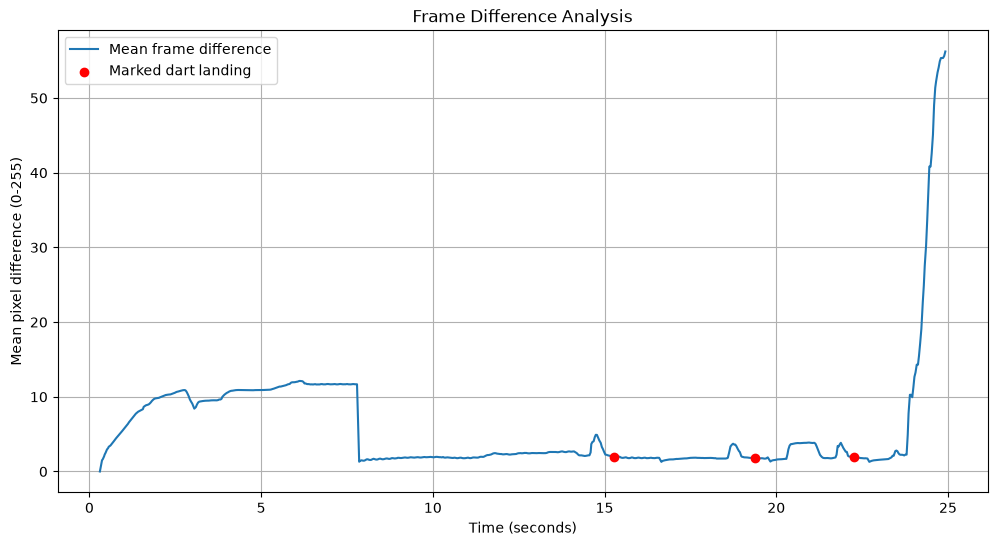

In [4]:

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("frame_differences.csv")

plt.figure(figsize=(12, 6))

plt.plot(
    df["time"],
    df["mean_difference"],
    label="Mean frame difference"
)

# Mark dart landing events
dart_events = df[df["dart_landed"] == 1]

plt.scatter(
    dart_events["time"],
    dart_events["mean_difference"],
    color="red",
    label="Marked dart landing",
    zorder=5
)

plt.xlabel("Time (seconds)")
plt.ylabel("Mean pixel difference (0-255)")
plt.title("Frame Difference Analysis")
plt.legend()
plt.grid(True)
plt.show()


# Event detection on recorded video

In [5]:

"""Record frame differences to determine an optimal detection threshold.

SPACE = Mark a dart landing
R     = Reset reference frame
Q     = Quit and save
"""

import cv2
import numpy as np
import csv
import time

VIDEO_PATH = r"..\data\dart_videos\dart_2_2point.mp4"
CAMERA_ON = False
CAMERA_INDEX = 0

DISPLAY_WIDTH = 640
DISPLAY_HEIGHT = 640

CSV_PATH = "frame_differences.csv"


def main():
    path = CAMERA_INDEX if CAMERA_ON else VIDEO_PATH
    cap = cv2.VideoCapture(path)

    if not cap.isOpened():
        raise RuntimeError(f"Cannot open video: {path}")

    reference_frame = None
    measurements = []
    frame_count = 0
    max_difference = 0.0
    start_time = time.time()

    try:
        while True:
            ret, frame = cap.read()

            if not ret:
                break

            frame_count += 1

            if reference_frame is None:
                reference_frame = frame.copy()

            # Calculate frame difference
            difference = cv2.absdiff(frame, reference_frame)
            gray_difference = cv2.cvtColor(
                difference, cv2.COLOR_BGR2GRAY
            )

            mean_difference = float(np.mean(difference))
            max_pixel_difference = int(np.max(gray_difference))

            # Percentage of pixels changed significantly
            changed_percentage = float(
                np.mean(gray_difference > 30) * 100
            )

            max_difference = max(
                max_difference, mean_difference
            )

            timestamp = time.time() - start_time

            # Store measurements
            measurement = {
                "frame": frame_count,
                "time": round(timestamp, 3),
                "mean_difference": round(mean_difference, 3),
                "max_pixel_difference": max_pixel_difference,
                "changed_percentage": round(changed_percentage, 3),
                "dart_landed": 0
            }

            measurements.append(measurement)

            # Prepare display
            original_display = cv2.resize(
                frame.copy(),
                (DISPLAY_WIDTH, DISPLAY_HEIGHT)
            )

            difference_display = cv2.resize(
                gray_difference,
                (DISPLAY_WIDTH, DISPLAY_HEIGHT)
            )

            difference_display = cv2.cvtColor(
                difference_display, cv2.COLOR_GRAY2BGR
            )

            # Display measurements
            cv2.putText(
                original_display,
                f"Mean difference: {mean_difference:.2f}",
                (20, 40),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7, (0, 255, 0), 2
            )

            cv2.putText(
                original_display,
                f"Max difference: {max_difference:.2f}",
                (20, 80),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7, (0, 255, 0), 2
            )

            cv2.putText(
                original_display,
                f"Changed pixels: {changed_percentage:.2f}%",
                (20, 120),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7, (0, 255, 0), 2
            )

            combined = np.hstack(
                (original_display, difference_display)
            )

            cv2.imshow("Frame Difference Analysis", combined)

            key = cv2.waitKey(5) & 0xFF

            if key == ord("q"):
                break

            elif key == ord("r"):
                
                reference_frame = frame.copy()
                print("Reference frame reset")

            elif key == 32:
                measurements[-1]["dart_landed"] = 1
                print(
                    f"Dart marked at frame {frame_count}, "
                    f"difference = {mean_difference:.2f}"
                )

    finally:
        cap.release()
        cv2.destroyAllWindows()

        # Save measurements
        if measurements:
            with open(CSV_PATH, "w", newline="") as file:
                writer = csv.DictWriter(
                    file,
                    fieldnames=measurements[0].keys()
                )
                writer.writeheader()
                writer.writerows(measurements)

            print(f"\nMeasurements saved to {CSV_PATH}")
            print(f"Maximum mean difference: {max_difference:.2f}")


if __name__ == "__main__":
    main()



Measurements saved to frame_differences.csv
Maximum mean difference: 6.87


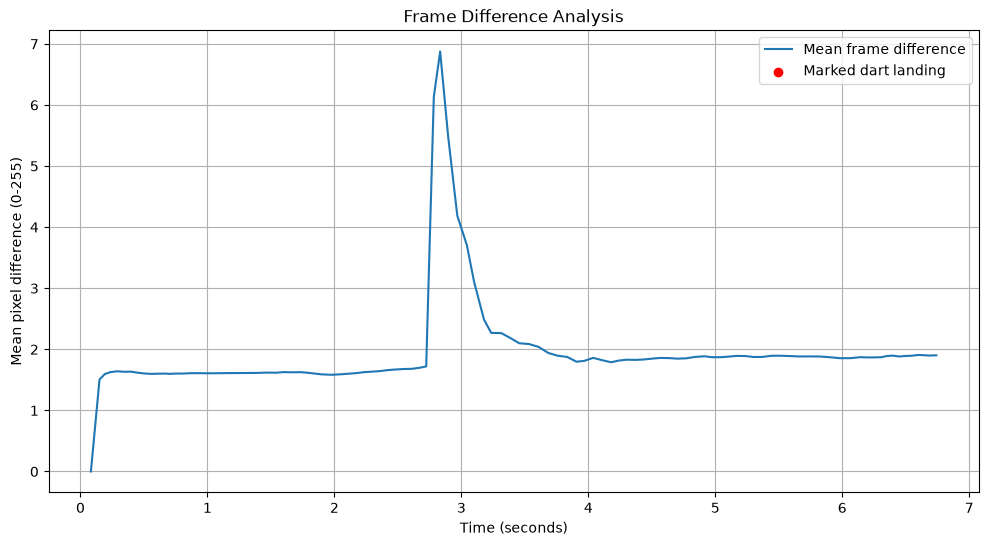

In [6]:

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("frame_differences.csv")

plt.figure(figsize=(12, 6))

plt.plot(
    df["time"],
    df["mean_difference"],
    label="Mean frame difference"
)

# Mark dart landing events
dart_events = df[df["dart_landed"] == 1]

plt.scatter(
    dart_events["time"],
    dart_events["mean_difference"],
    color="red",
    label="Marked dart landing",
    zorder=5
)

plt.xlabel("Time (seconds)")
plt.ylabel("Mean pixel difference (0-255)")
plt.title("Frame Difference Analysis")
plt.legend()
plt.grid(True)
plt.show()


## **CHAT CODED**

In [59]:

"""Dartboard detection and automatic reference updating.

SPACE = Manually mark dart landing
R     = Reset reference frame
Q     = Quit and save CSV
"""

import cv2
import numpy as np
import csv
import time

from Board import DartBoard


# ---------------- CONFIGURATION ----------------

VIDEO_PATH = r"..\data\dart_videos\doubledart_25_12_37point.mp4"

CAMERA_ON = False
CAMERA_INDEX = 0

DISPLAY_WIDTH = 480
DISPLAY_HEIGHT = 480

INITIAL_FRAMES = 10
RETRY_EVERY_N_FRAMES = 30
CACHE_BOARD = True

CSV_PATH = "frame_differences.csv"

PIXEL_CHANGE_THRESHOLD = 30

# Automatic reference updating
AUTO_UPDATE_REFERENCE = True

CHANGE_THRESHOLD = 0.02
STABILITY_THRESHOLD = 0.2
STABLE_FRAMES_REQUIRED = 10

# Ignore small changes and wait for movement to stop
MIN_CHANGE_PERCENTAGE = 0.1


# ---------------- HELPER FUNCTIONS ----------------

def resize_display(image):
    return cv2.resize(
        image,
        (DISPLAY_WIDTH, DISPLAY_HEIGHT)
    )


def add_label(image, label):
    cv2.putText(
        image,
        label,
        (15, 35),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (0, 255, 0),
        2
    )
    return image


def calculate_difference(current, reference, mask):
    """Calculate image differences inside the dartboard mask."""

    current = cv2.cvtColor(
            current,
            cv2.COLOR_BGR2GRAY
        )    

    reference = cv2.cvtColor(
            reference,
            cv2.COLOR_BGR2GRAY
        )    
    
    clahe = cv2.createCLAHE(clipLimit=5, tileGridSize=(20,20))
    
    current = clahe.apply(current)
    reference = clahe.apply(reference)
    
    gray_difference = cv2.absdiff(current, reference)

 
    gray_difference = cv2.GaussianBlur(gray_difference, (0,0), 1.5)
    # gray_difference = clahe.apply(gray_difference)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))

    opened = cv2.morphologyEx(gray_difference, cv2.MORPH_OPEN, kernel)

    gray_difference = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, kernel)
    ### Edges

    # gray_difference = cv2.Canny(gray_difference, 150, 200)



    valid_pixels = mask > 0

    if not np.any(valid_pixels):
        raise ValueError("Dartboard mask contains no valid pixels")

    mean_difference = cv2.mean(
        gray_difference,
        mask=mask
    )[0]

    normalized_difference = mean_difference / 255.0

    max_pixel_difference = int(
        np.max(gray_difference[valid_pixels])
    )

    changed_percentage = float(
        np.mean(
            gray_difference[valid_pixels]
            > PIXEL_CHANGE_THRESHOLD
        ) * 100
    )

    return (
        gray_difference,
        mean_difference,
        normalized_difference,
        max_pixel_difference,
        changed_percentage
    )


# ---------------- MAIN PROGRAM ----------------

def main():

    path = CAMERA_INDEX if CAMERA_ON else VIDEO_PATH

    cap = cv2.VideoCapture(path)

    if not cap.isOpened():
        raise RuntimeError(f"Cannot open video: {path}")

    board = DartBoard()

    init_frames = []

    reference_board = None
    previous_board = None

    change_detected = False
    stable_frames = 0

    measurements = []

    frame_count = 0
    max_difference = 0.0

    start_time = time.time()

    try:

        while True:

            ret, frame = cap.read()

            if not ret:
                break

            frame_count += 1

            # ---------------- BOARD CALIBRATION ----------------

            board.update_frame(frame)

            if len(init_frames) < INITIAL_FRAMES:

                init_frames.append(frame.copy())

                print(
                    f"Collected initial frames: "
                    f"{len(init_frames)}/{INITIAL_FRAMES}"
                )

                if len(init_frames) == INITIAL_FRAMES:

                    board.calibrate(init_frames)

                    print("Board calibration completed")

            # Default values before calibration
            mean_difference = 0.0
            normalized_difference = 0.0
            max_pixel_difference = 0
            changed_percentage = 0.0
            motion_level = 0.0
            reference_updated = 0

            status = "CALIBRATING"

            # ---------------- BOARD DETECTION ----------------

            if board.board_homography is not None:

                if (
                    not CACHE_BOARD
                    or board.field_map is None
                    or frame_count % RETRY_EVERY_N_FRAMES == 0
                ):
                    board.detect()

                processed = board.draw()

                # Extract only the inner dartboard
                inner_board, mask = board.get_inner_board(
                    return_mask=True
                )

                # Initialize reference image
                if (
                    reference_board is None
                    or reference_board.shape != inner_board.shape
                ):

                    reference_board = inner_board.copy()
                    previous_board = inner_board.copy()

                    change_detected = False
                    stable_frames = 0

                # ---------------- REFERENCE DIFFERENCE ----------------

                (
                    gray_difference,
                    mean_difference,
                    normalized_difference,
                    max_pixel_difference,
                    changed_percentage
                ) = calculate_difference(
                    inner_board,
                    reference_board,
                    mask
                )

                max_difference = max(
                    max_difference,
                    mean_difference
                )

                # ---------------- MOTION DIFFERENCE ----------------

                motion_difference = cv2.absdiff(
                    inner_board,
                    previous_board
                )

                motion_gray = cv2.cvtColor(
                    motion_difference,
                    cv2.COLOR_BGR2GRAY
                )

                motion_level = cv2.mean(
                    motion_gray,
                    mask=mask
                )[0] / 255.0

                # ---------------- AUTOMATIC REFERENCE UPDATE ----------------

                status = "MONITORING"

                if AUTO_UPDATE_REFERENCE:

                    # Detect a significant change
                    if not change_detected:

                        if (
                            normalized_difference > CHANGE_THRESHOLD
                            and changed_percentage > MIN_CHANGE_PERCENTAGE
                        ):

                            change_detected = True
                            stable_frames = 0

                            print(
                                f"Change detected at frame {frame_count}"
                            )

                    # Wait for the board to become stable
                    if change_detected:

                        status = "WAITING FOR STABILITY"

                        if motion_level < STABILITY_THRESHOLD:

                            stable_frames += 1

                        else:

                            stable_frames = 0

                        # Update reference after stable frames
                        if stable_frames >= STABLE_FRAMES_REQUIRED:

                            reference_board = inner_board.copy()

                            change_detected = False
                            stable_frames = 0

                            reference_updated = 1

                            status = "REFERENCE UPDATED"

                            print(
                                f"Reference automatically updated "
                                f"at frame {frame_count}"
                            )

                # Update previous frame every iteration
                previous_board = inner_board.copy()

                # ---------------- DIFFERENCE DISPLAY ----------------

                difference_display = cv2.cvtColor(
                    gray_difference,
                    cv2.COLOR_GRAY2BGR
                )

                # Highlight changed pixels
                changed_mask = (
                    (gray_difference > PIXEL_CHANGE_THRESHOLD)
                    & (mask > 0)
                )

                difference_display[changed_mask] = (0, 0, 255)

                # ---------------- RECORD MEASUREMENTS ----------------

                timestamp = time.time() - start_time

                measurement = {
                    "frame": frame_count,
                    "time": round(timestamp, 3),
                    "mean_difference": round(mean_difference, 3),
                    "normalized_difference": round(
                        normalized_difference, 5
                    ),
                    "max_pixel_difference": max_pixel_difference,
                    "changed_percentage": round(
                        changed_percentage, 3
                    ),
                    "motion_level": round(motion_level, 5),
                    "change_detected": int(change_detected),
                    "stable_frames": stable_frames,
                    "reference_updated": reference_updated,
                    "dart_landed": 0
                }

                measurements.append(measurement)

            else:

                processed = frame.copy()

                difference_display = np.zeros_like(frame)

            # ---------------- DISPLAY ----------------

            original_display = resize_display(frame.copy())
            processed_display = resize_display(processed)
            difference_display = resize_display(
                difference_display
            )

            original_display = add_label(
                original_display,
                "Original"
            )

            processed_display = add_label(
                processed_display,
                "Processed"
            )

            difference_display = add_label(
                difference_display,
                "Difference"
            )

            # Display statistics
            cv2.putText(
                difference_display,
                f"Mean: {mean_difference:.2f}",
                (15, 75),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.55,
                (0, 255, 0),
                2
            )

            cv2.putText(
                difference_display,
                f"Normalized: {normalized_difference:.4f}",
                (15, 105),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.55,
                (0, 255, 0),
                2
            )

            cv2.putText(
                difference_display,
                f"Changed: {changed_percentage:.2f}%",
                (15, 135),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.55,
                (0, 255, 0),
                2
            )

            cv2.putText(
                difference_display,
                f"Motion: {motion_level:.4f}",
                (15, 165),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.55,
                (0, 255, 0),
                2
            )

            cv2.putText(
                difference_display,
                f"Stable: {stable_frames}/{STABLE_FRAMES_REQUIRED}",
                (15, 195),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.55,
                (0, 255, 0),
                2
            )

            cv2.putText(
                difference_display,
                f"Max mean: {max_difference:.2f}",
                (15, 225),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.55,
                (0, 255, 0),
                2
            )

            # Display status
            status_color = (0, 255, 0)

            if change_detected:
                status_color = (0, 255, 255)

            if reference_updated:
                status_color = (255, 255, 0)

            cv2.putText(
                difference_display,
                status,
                (15, 265),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.55,
                status_color,
                2
            )

            # Combine displays
            combined = np.hstack((
                original_display,
                processed_display,
                difference_display
            ))

            cv2.imshow(
                "Dartboard Difference Analysis",
                combined
            )

            # ---------------- KEYBOARD CONTROLS ----------------

            key = cv2.waitKey(5) & 0xFF

            if key == ord("q"):
                break

            elif key == ord("r"):

                if board.board_homography is not None:

                    reference_board = inner_board.copy()
                    previous_board = inner_board.copy()

                    change_detected = False
                    stable_frames = 0

                    print("Reference board manually reset")

            elif key == 32:

                if measurements:

                    measurements[-1]["dart_landed"] = 1

                    print(
                        f"Dart marked at frame {frame_count} | "
                        f"Mean: {mean_difference:.2f} | "
                        f"Changed: {changed_percentage:.2f}%"
                    )

    finally:

        cap.release()
        cv2.destroyAllWindows()

        # ---------------- SAVE CSV ----------------

        if measurements:

            with open(
                CSV_PATH,
                "w",
                newline=""
            ) as file:

                writer = csv.DictWriter(
                    file,
                    fieldnames=measurements[0].keys()
                )

                writer.writeheader()
                writer.writerows(measurements)

            print(f"\nMeasurements saved to: {CSV_PATH}")
            print(f"Maximum mean difference: {max_difference:.2f}")


if __name__ == "__main__":
    main()


Collected initial frames: 1/10
Collected initial frames: 2/10
Collected initial frames: 3/10
Collected initial frames: 4/10
Collected initial frames: 5/10
Collected initial frames: 6/10
Collected initial frames: 7/10
Collected initial frames: 8/10
Collected initial frames: 9/10
Collected initial frames: 10/10
Board calibration completed
Change detected at frame 37
Reference automatically updated at frame 46
Change detected at frame 49
Reference automatically updated at frame 58
Change detected at frame 124
Reference automatically updated at frame 133
Change detected at frame 135
Reference automatically updated at frame 144
Change detected at frame 146
Reference automatically updated at frame 155

Measurements saved to: frame_differences.csv
Maximum mean difference: 11.99


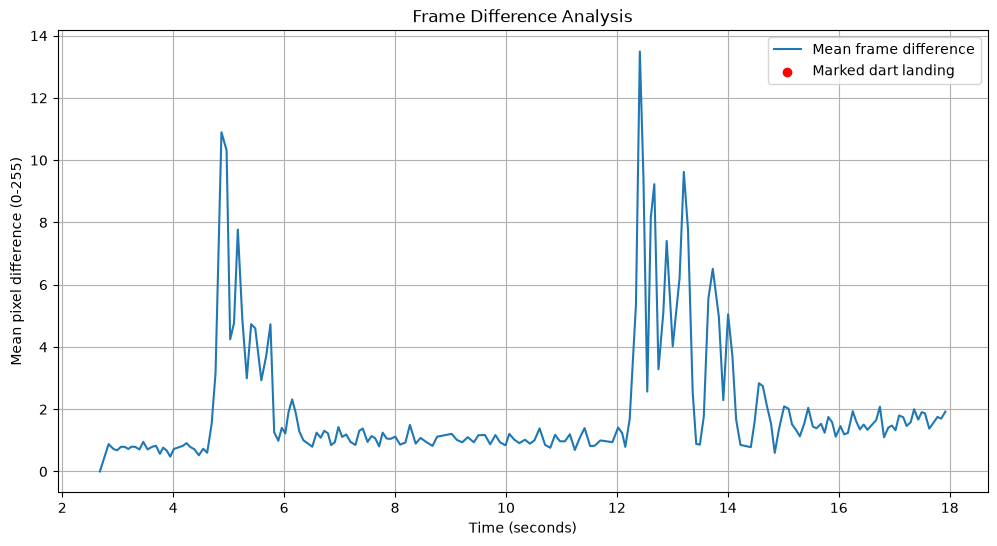

In [56]:

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("frame_differences.csv")

plt.figure(figsize=(12, 6))

plt.plot(
    df["time"],
    df["mean_difference"],
    label="Mean frame difference"
)

# Mark dart landing events
dart_events = df[df["dart_landed"] == 1]

plt.scatter(
    dart_events["time"],
    dart_events["mean_difference"],
    color="red",
    label="Marked dart landing",
    zorder=5
)

plt.xlabel("Time (seconds)")
plt.ylabel("Mean pixel difference (0-255)")
plt.title("Frame Difference Analysis")
plt.legend()
plt.grid(True)
plt.show()
